# Evernorth Clinical CDS — Milestone 1.1: Modeling Readiness Gate
### Research Prototype: Clinical Decision Support Using Deep Learning and NLP

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hemanthsai456/Clinical-DSS/blob/main/notebooks/01_data_audit.ipynb)

> **Important Regulatory & Scope Notice:**  
> This software is an **educational research prototype** developed for investigating machine learning and NLP methods in clinical decision support. It is **not** a clinically validated medical product and must **not** be used for diagnostic, treatment, or clinical patient management decisions. Never upload real, unprotected patient health information (PHI) or commit raw patient datasets to version control.

---

## Notebook Overview & Running Instructions

### How to run this notebook in Google Colab:
1. Click the **Open In Colab** badge above.
2. In the first code cell, execute the installation block to install required packages (`ucimlrepo`, `tabulate`, etc.).
3. If running in Colab without local storage, the data loader will automatically download the public datasets reproducibly from their official repositories (UCI Machine Learning Repository and Hugging Face).
4. Run all cells sequentially (**Runtime -> Run all**).

### How to run this notebook locally:
1. Ensure your virtual environment is active: `pip install -r requirements.txt`
2. Run Jupyter: `jupyter lab` or `jupyter notebook`
3. The loaders will automatically locate local files in `D:/Evernorth/UCI-Diabetes` and `D:/Evernorth/Synth-SBDH` (or paths set via `UCI_DATA_PATH` and `SYNTH_SBDH_DATA_DIR`).

---
## Section A: Environment Setup & Reproducibility

To ensure strict reproducibility:
- Random seeds are fixed across standard library and NumPy.
- Package versions are profiled and logged.
- Path discovery prioritizes local cached files before attempting any network download.

In [1]:
# Environment & Library Setup
import sys
import os

# Check if running in Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Running in Google Colab environment. Installing necessary packages...")
    !pip install -q ucimlrepo tabulate
    # Clone repository or add to path if needed
    if not os.path.exists("src"):
        !git clone https://github.com/Hemanthsai456/Clinical-DSS.git
        %cd Clinical-DSS
    sys.path.insert(0, os.path.abspath("."))
else:
    print("Running in local environment.")
    # Ensure repository root is on sys.path
    repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(".")
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)

# Standard library and third-party imports
import random
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit

# Project modules
from src.utils import set_seeds, get_environment_info, save_json
from src.data_loaders import (
    load_uci_diabetes,
    load_synth_sbdh,
    load_uci_ids_mapping,
    find_uci_diabetes_path,
    find_synth_sbdh_dir
)
from src.audit_uci import (
    audit_uci_dataset,
    split_uci_patient_grouped,
    create_eligible_modeling_cohort,
    parse_ids_mapping_dispositions,
    FEATURE_TEMPORAL_TAXONOMY
)
from src.audit_synth_sbdh import (
    audit_synth_sbdh_all,
    recover_character_offsets
)

# Set global aesthetics and seeds
set_seeds(42)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("Environment initialized successfully.")

Running in local environment.


Environment initialized successfully.


In [2]:
# Display Package Versions & System Profile
env_info = get_environment_info()
print(f"Python Version: {env_info['python_version']}")
print(f"Platform:       {env_info['platform']}")
print(f"In Colab:       {env_info['is_colab']}")
print("\nPackage Versions:")
for pkg, ver in env_info['packages'].items():
    print(f"  {pkg:18s}: {ver}")

Python Version: 3.11.3
Platform:       win32
In Colab:       False

Package Versions:
  pandas            : 2.2.3
  numpy             : 2.1.3
  sklearn           : 1.6.1
  requests          : 2.32.3
  matplotlib        : 3.10.6
  seaborn           : 0.13.2
  huggingface_hub   : 1.28.0
  ucimlrepo         : not_installed
  nbformat          : 5.10.4


---
## Section B: UCI Diabetes 130-US Hospitals (1999–2008) Audit & Cohort Policy

### Clinical Objective, Prediction Horizon & Feature Policy
- **Source:** [UCI Machine Learning Repository (Dataset 296)](https://archive.ics.uci.edu/dataset/296/diabetes%2B130-us-hospitals-for-years-1999-2008)
- **Intended Prediction Time:** **Discharge (Transitional Care Management Planning)**.
  - The model flags high-risk diabetic patients at the point of discharge planning to trigger post-acute care interventions, home health monitoring, and medication reconciliation.
  - At discharge, in-hospital duration (`time_in_hospital`), procedure/lab intensity, and medication changes are fully documented.
- **Identifiers Policy:** `encounter_id` and `patient_nbr` are strictly excluded from model inputs and preserved solely for longitudinal linking and patient-grouped splitting.
- **Laboratory Result Category Preservation:** Literal `"None"` in `max_glu_serum` (96,420 encounters) and `A1Cresult` (84,748 encounters) represents **"Test Not Performed/Measured"**. It is a valid, clinically informative category with **0.00% missingness**, NOT a corrupted missing value. Only actual missing-value markers (`?`) are converted to missing.
- **Feature Pipeline Sensitivity Analysis:** `discharge_disposition_id` is evaluated via an explicit sensitivity comparison: **Model Baseline A (without disposition ID)** versus **Model Baseline B (with disposition ID)** to assess post-acute placement leakage.

In [3]:
# Load UCI Diabetes Dataset and IDs Mapping
uci_df, uci_path = load_uci_diabetes(allow_download=True if IN_COLAB else None)
print(f"UCI Dataset loaded from: {uci_path}")
print(f"Dimensions: {uci_df.shape[0]:,} rows (encounters) x {uci_df.shape[1]} columns")

# Assert and verify literal 'None' preservation in lab tests (0% missing)
assert uci_df["max_glu_serum"].isna().sum() == 0, "max_glu_serum contains NaNs; 'None' was incorrectly converted to missing!"
assert "None" in uci_df["max_glu_serum"].values, "'None' category missing from max_glu_serum!"
assert uci_df["A1Cresult"].isna().sum() == 0, "A1Cresult contains NaNs; 'None' was incorrectly converted to missing!"
assert "None" in uci_df["A1Cresult"].values, "'None' category missing from A1Cresult!"

print("\n--- Laboratory Result Category Verification (0% Missing) ---")
print("max_glu_serum missing:", uci_df["max_glu_serum"].isna().sum(), f"(0.00%) | Values: {uci_df['max_glu_serum'].value_counts().to_dict()}")
print("A1Cresult missing:    ", uci_df["A1Cresult"].isna().sum(), f"(0.00%) | Values: {uci_df['A1Cresult'].value_counts().to_dict()}")
print("-> Confirmed: Literal 'None' is preserved as valid category 'Test Not Performed/Measured' (not NaN).")

ids_path = os.path.join(os.path.dirname(uci_path), "IDS_mapping.csv") if os.path.exists(os.path.join(os.path.dirname(uci_path), "IDS_mapping.csv")) else None
if ids_path:
    print(f"\nIDs Mapping file found: {ids_path}")
else:
    print("\nIDs mapping file not found locally. Fallback verified codes will be applied.")

uci_df.head(3)

[UCI-Diabetes] Found local dataset at: D:\Evernorth\UCI-Diabetes\diabetic_data.csv (19,159,383 bytes)


UCI Dataset loaded from: D:\Evernorth\UCI-Diabetes\diabetic_data.csv
Dimensions: 101,766 rows (encounters) x 50 columns

--- Laboratory Result Category Verification (0% Missing) ---
max_glu_serum missing: 0 (0.00%) | Values: {'None': 96420, 'Norm': 2597, '>200': 1485, '>300': 1264}
A1Cresult missing:     0 (0.00%) | Values: {'None': 84748, '>8': 8216, 'Norm': 4990, '>7': 3812}
-> Confirmed: Literal 'None' is preserved as valid category 'Test Not Performed/Measured' (not NaN).

IDs Mapping file found: D:\Evernorth\UCI-Diabetes\IDS_mapping.csv


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO


In [4]:
# Dynamic Discharge Disposition Verification via IDS_mapping.csv
if ids_path:
    disposition_map, mortality_hospice_codes = parse_ids_mapping_dispositions(ids_path)
    print(f"Parsed {len(disposition_map)} discharge dispositions from IDS_mapping.csv.")
    print("\nVerified Mortality & Hospice Dispositions:")
    for code, desc in sorted(mortality_hospice_codes.items()):
        print(f"  Code {code:2d}: '{desc}'")
else:
    print("Using verified fallback mortality/hospice codes: [11, 13, 14, 19, 20, 21].")

Parsed 30 discharge dispositions from IDS_mapping.csv.

Verified Mortality & Hospice Dispositions:
  Code 11: 'Expired'
  Code 13: 'Hospice / home'
  Code 14: 'Hospice / medical facility'
  Code 19: 'Expired at home. Medicaid only, hospice.'
  Code 20: 'Expired in a medical facility. Medicaid only, hospice.'
  Code 21: 'Expired, place unknown. Medicaid only, hospice.'


--- Cohort Filtering Comparison Table ---
                   Metric Unfiltered Cohort Excluded (Death/Hospice) Eligible Modeling Cohort
         Total Encounters           101,766                    2,423                   99,343
          Unique Patients            71,518                    2,399                   69,990
Readmitted <30 (Positive)            11,357                       43                   11,314
           Readmitted >30            35,545                       43                   35,502
            Readmitted NO            54,864                    2,337                   52,527
Positive Prevalence (<30)            11.16%                    1.77%                   11.39%
Imbalance Ratio (Neg:Pos)          7.96 : 1                      N/A                 7.78 : 1

--- Detailed Investigation of the 86 Excluded Encounters with Readmission Labels ---
readmitted                <30  >30    NO   All
discharge_disposition_id                      
11                        

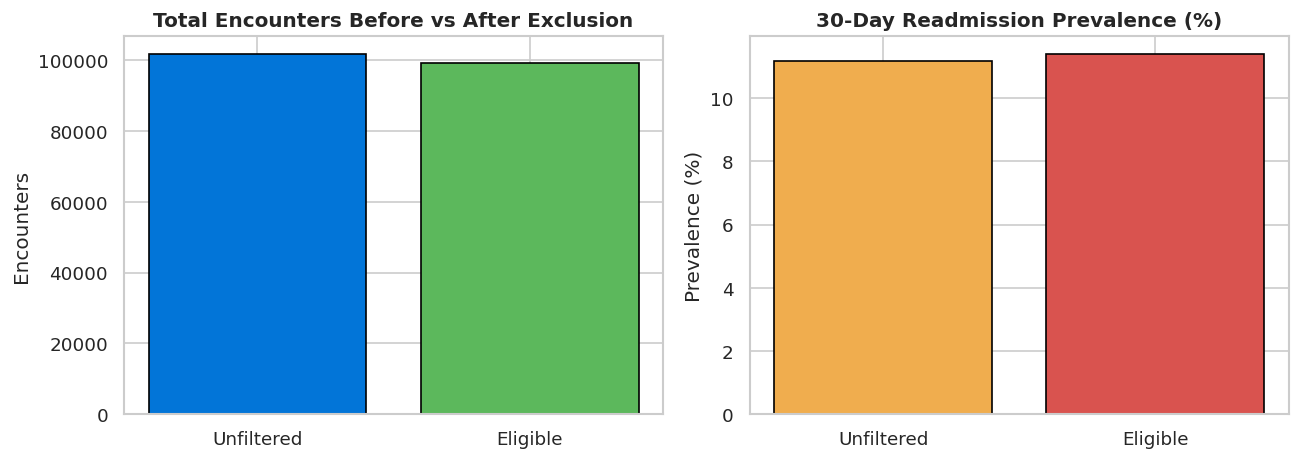

In [5]:
# Create Eligible Modeling Cohort & Compare Against Unfiltered Baseline
uci_audit = audit_uci_dataset(uci_df, ids_path=ids_path)
df_eligible, cohort_comparison = create_eligible_modeling_cohort(uci_df, ids_path=ids_path)

unf = cohort_comparison["unfiltered_cohort"]
exc = cohort_comparison["excluded_mortality_hospice"]
elg = cohort_comparison["eligible_modeling_cohort"]

comp_df = pd.DataFrame([
    {
        "Metric": "Total Encounters",
        "Unfiltered Cohort": f"{unf['total_encounters']:,}",
        "Excluded (Death/Hospice)": f"{exc['total_encounters']:,}",
        "Eligible Modeling Cohort": f"{elg['total_encounters']:,}"
    },
    {
        "Metric": "Unique Patients",
        "Unfiltered Cohort": f"{unf['unique_patients']:,}",
        "Excluded (Death/Hospice)": f"{exc['unique_patients']:,}",
        "Eligible Modeling Cohort": f"{elg['unique_patients']:,}"
    },
    {
        "Metric": "Readmitted <30 (Positive)",
        "Unfiltered Cohort": f"{unf['positive_count_lt30']:,}",
        "Excluded (Death/Hospice)": f"{exc['positive_count_lt30']:,}",
        "Eligible Modeling Cohort": f"{elg['positive_count_lt30']:,}"
    },
    {
        "Metric": "Readmitted >30",
        "Unfiltered Cohort": f"{unf['target_counts'].get('>30', 0):,}",
        "Excluded (Death/Hospice)": f"{exc['target_counts'].get('>30', 0):,}",
        "Eligible Modeling Cohort": f"{elg['target_counts'].get('>30', 0):,}"
    },
    {
        "Metric": "Readmitted NO",
        "Unfiltered Cohort": f"{unf['target_counts'].get('NO', 0):,}",
        "Excluded (Death/Hospice)": f"{exc['target_counts'].get('NO', 0):,}",
        "Eligible Modeling Cohort": f"{elg['target_counts'].get('NO', 0):,}"
    },
    {
        "Metric": "Positive Prevalence (<30)",
        "Unfiltered Cohort": f"{unf['positive_prevalence_pct']:.2f}%",
        "Excluded (Death/Hospice)": f"{exc['positive_prevalence_pct']:.2f}%",
        "Eligible Modeling Cohort": f"{elg['positive_prevalence_pct']:.2f}%"
    },
    {
        "Metric": "Imbalance Ratio (Neg:Pos)",
        "Unfiltered Cohort": f"{(unf['total_encounters'] - unf['positive_count_lt30']) / unf['positive_count_lt30']:.2f} : 1",
        "Excluded (Death/Hospice)": "N/A",
        "Eligible Modeling Cohort": f"{elg['imbalance_ratio']:.2f} : 1"
    }
])

print("--- Cohort Filtering Comparison Table ---")
print(comp_df.to_string(index=False))

# Detailed Investigation of the 86 Readmitted Encounters in the Excluded Cohort
excluded_codes = sorted(list(cohort_comparison["verified_exclusion_codes"].keys()))
df_excluded = uci_df[uci_df["discharge_disposition_id"].isin(excluded_codes)]
df_hosp_readmit = df_excluded[df_excluded["readmitted"].isin(["<30", ">30"])]

print(f"\n--- Detailed Investigation of the {len(df_hosp_readmit)} Excluded Encounters with Readmission Labels ---")
crosstab_disp = pd.crosstab(df_excluded["discharge_disposition_id"], df_excluded["readmitted"], margins=True)
print(crosstab_disp)

d13_lt = int(((df_excluded["discharge_disposition_id"] == 13) & (df_excluded["readmitted"] == "<30")).sum())
d13_gt = int(((df_excluded["discharge_disposition_id"] == 13) & (df_excluded["readmitted"] == ">30")).sum())
d14_lt = int(((df_excluded["discharge_disposition_id"] == 14) & (df_excluded["readmitted"] == "<30")).sum())
d14_gt = int(((df_excluded["discharge_disposition_id"] == 14) & (df_excluded["readmitted"] == ">30")).sum())
true_deaths_readmit = int((df_excluded["discharge_disposition_id"].isin([11, 19, 20, 21]) & (df_excluded["readmitted"] != "NO")).sum())

print("\nBreakdown Analysis:")
print(f"  - Code 13 ('Hospice / home'):             {d13_lt} (<30d) + {d13_gt} (>30d) = {d13_lt + d13_gt} total")
print(f"  - Code 14 ('Hospice / medical facility'): {d14_lt} (<30d) + {d14_gt} (>30d) = {d14_lt + d14_gt} total")
print(f"  - Codes 11, 19, 20, 21 (True Deaths):     {true_deaths_readmit} with readmission label (All 2,337 are 'NO')")

er_count = int((df_hosp_readmit["admission_source_id"] == 7).sum())
print(f"\nClinical Profile of the 86 Encounters:")
print(f"  - Unique Patients: {df_hosp_readmit['patient_nbr'].nunique()}")
print(f"  - Emergency Room Admissions (source=7): {er_count} / {len(df_hosp_readmit)} ({er_count / len(df_hosp_readmit) * 100:.1f}%)")
print(f"  - Top Diagnoses: {df_hosp_readmit['diag_1'].value_counts().head(5).to_dict()} (CHF: 428, AMI: 410, Sepsis: 38, Cancer: 197/162)")
print(f"  - Conclusion: NOT MISCODED. Genuine clinical hospice crisis readmissions; excluded under CMS HRRP policy.")

# Plot Cohort Comparison
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(["Unfiltered", "Eligible"], [unf['total_encounters'], elg['total_encounters']], color=['#0275d8', '#5cb85c'], edgecolor='black')
ax[0].set_title("Total Encounters Before vs After Exclusion", fontweight='bold')
ax[0].set_ylabel("Encounters")

ax[1].bar(["Unfiltered", "Eligible"], [unf['positive_prevalence_pct'], elg['positive_prevalence_pct']], color=['#f0ad4e', '#d9534f'], edgecolor='black')
ax[1].set_title("30-Day Readmission Prevalence (%)", fontweight='bold')
ax[1].set_ylabel("Prevalence (%)")
plt.tight_layout()
plt.show()

In [6]:
# Target Formulation & Semantic Clarification
print("--- Target Semantics & Definitions ---")
print("Target Variable: 'readmitted'")
print("  - '<30': Positive Class (1) -> Early unplanned readmission within 30 days.")
print("  - '>30': Negative Class (0) -> Late readmission (after 30 days).")
print("  - 'NO':  Negative Class (0) -> No recorded readmission in dataset.")
print("\nCritical Clinical Distinction:")
print("  'NO' signifies NO RECORDED READMISSION within the 130 participating hospitals")
print("  during the 1999-2008 study window. It is NOT proof of non-hospitalization elsewhere")
print("  or non-mortality post-discharge.")

--- Target Semantics & Definitions ---
Target Variable: 'readmitted'
  - '<30': Positive Class (1) -> Early unplanned readmission within 30 days.
  - '>30': Negative Class (0) -> Late readmission (after 30 days).
  - 'NO':  Negative Class (0) -> No recorded readmission in dataset.

Critical Clinical Distinction:
  'NO' signifies NO RECORDED READMISSION within the 130 participating hospitals
  during the 1999-2008 study window. It is NOT proof of non-hospitalization elsewhere
  or non-mortality post-discharge.


In [7]:
# Longitudinal Patient Analysis on Eligible Cohort
enc_counts = df_eligible.groupby("patient_nbr")["encounter_id"].count()
n_single = (enc_counts == 1).sum()
n_multi = (enc_counts > 1).sum()

print(f"Eligible Encounters: {len(df_eligible):,}")
print(f"Unique Patients:     {len(enc_counts):,}")
print(f"Single-Encounter Patients:    {n_single:,} ({n_single / len(enc_counts) * 100:.2f}%)")
print(f"Multiple-Encounter Patients:  {n_multi:,} ({n_multi / len(enc_counts) * 100:.2f}%)")
print(f"Maximum Encounters (1 Pat):   {enc_counts.max()}")

Eligible Encounters: 99,343
Unique Patients:     69,990
Single-Encounter Patients:    53,649 (76.65%)
Multiple-Encounter Patients:  16,341 (23.35%)
Maximum Encounters (1 Pat):   40


In [8]:
# Feature Pipeline Policy & Sensitivity Analysis Specification
print("--- UCI Feature Pipeline Policy & Sensitivity Plan ---")
print("1. Prediction-Time Assumption: DISCHARGE (Transitional Care Management Planning).")
print("   At discharge, full inpatient duration (time_in_hospital), procedure counts, in-hospital")
print("   lab test results, and inpatient medication changes are fully documented.")
print("\n2. Identifiers Policy:")
print("   'encounter_id' and 'patient_nbr' are STRICTLY EXCLUDED from model features.")
print("   Preserved solely for patient-grouped cross-validation splitting and audit tracking.")
print("\n3. Administrative & Heavily-Missing Features:")
print("   'weight' (96.86% missing) and 'payer_code' (39.56% missing) are dropped from modeling.")
print("\n4. Explicit Sensitivity Comparison Plan:")
print("   - Model Baseline A (Clinical Features Baseline): WITHOUT 'discharge_disposition_id'.")
print("   - Model Baseline B (Augmented Placement Model): WITH 'discharge_disposition_id'.")
print("   - This sensitivity test directly quantifies the lift versus circular placement leakage risk.")
print("   - Similarly, final billing ICD-9 codes ('diag_1', 'diag_2', 'diag_3') will be evaluated")
print("     with and without discharge coding to assess post-hoc coding lookahead bias.")

--- UCI Feature Pipeline Policy & Sensitivity Plan ---
1. Prediction-Time Assumption: DISCHARGE (Transitional Care Management Planning).
   At discharge, full inpatient duration (time_in_hospital), procedure counts, in-hospital
   lab test results, and inpatient medication changes are fully documented.

2. Identifiers Policy:
   'encounter_id' and 'patient_nbr' are STRICTLY EXCLUDED from model features.
   Preserved solely for patient-grouped cross-validation splitting and audit tracking.

3. Administrative & Heavily-Missing Features:
   'weight' (96.86% missing) and 'payer_code' (39.56% missing) are dropped from modeling.

4. Explicit Sensitivity Comparison Plan:
   - Model Baseline A (Clinical Features Baseline): WITHOUT 'discharge_disposition_id'.
   - Model Baseline B (Augmented Placement Model): WITH 'discharge_disposition_id'.
   - This sensitivity test directly quantifies the lift versus circular placement leakage risk.
   - Similarly, final billing ICD-9 codes ('diag_1', 'diag_

In [9]:
# Patient-Grouped Split on Eligible Modeling Cohort
train_df, val_df, test_df, split_metrics = split_uci_patient_grouped(
    df_eligible, test_size=0.15, val_size=0.15, random_state=42
)

print("--- Patient-Grouped Partitioning Results (Eligible Cohort) ---")
for split_name in ["train", "validation", "test"]:
    m = split_metrics[split_name]
    print(f"[{split_name.upper():10s}] Encounters: {m['encounters']:6,d} | Patients: {m['patients']:6,d} | Positive Rate: {m['positive_rate_pct']:.2f}%")

print(f"\nOverlap Verification: {split_metrics['overlap_verification']['status']}")
print(f"Protocol Rule: {split_metrics['protocol_rule']}")

--- Patient-Grouped Partitioning Results (Eligible Cohort) ---
[TRAIN     ] Encounters: 69,470 | Patients: 48,992 | Positive Rate: 11.45%
[VALIDATION] Encounters: 15,022 | Patients: 10,499 | Positive Rate: 11.39%
[TEST      ] Encounters: 14,851 | Patients: 10,499 | Positive Rate: 11.11%

Overlap Verification: PASSED - ZERO PATIENT LEAKAGE
Protocol Rule: Do NOT fit encoders, imputers, scalers, or feature selectors on the test set. All transformations must be fitted solely on the training partition and applied to val/test.


---
## Section C: Synth-SBDH Evaluation Contract & Span Alignment

### Evaluation Contract & Protocol
- **Source:** [Hugging Face: bio-nlp-umass/Synth-SBDH](https://huggingface.co/datasets/bio-nlp-umass/Synth-SBDH)
- **Primary Final Benchmark:** The **expert-reviewed test set** (`synth_sbdh_test_reviewed.csv`, 1,732 rows) is designated as the gold-standard evaluation set. It must remain strictly isolated from training, preprocessing fitting, and model selection.
- **Role of `Operation`:** The `Operation` column (`keep`, `add`, `correct`) is curation provenance metadata. It is **never** used as a feature, input, or prediction target.
- **Cross-Split Relationship:** `train`, `val`, and `test` are mutually independent with 0 text overlap. The `test_reviewed` set is an intentionally related, curated subset of `test`.

In [10]:
# Load Synth-SBDH Splits
synth_dfs, synth_dir = load_synth_sbdh(allow_download=True if IN_COLAB else None)
print(f"Synth-SBDH directory: {synth_dir}")
for split_name, df in synth_dfs.items():
    print(f"Split [{split_name:13s}]: {df.shape[0]:,d} rows x {df.shape[1]} columns")

[Synth-SBDH] Found local dataset directory at: D:\Evernorth\Synth-SBDH
Synth-SBDH directory: D:\Evernorth\Synth-SBDH
Split [train        ]: 6,136 rows x 7 columns
Split [val          ]: 876 rows x 7 columns
Split [test         ]: 1,755 rows x 7 columns
Split [test_reviewed]: 1,732 rows x 8 columns


In [11]:
# Run Comprehensive Audit & Contract Assertions
synth_audit = audit_synth_sbdh_all(synth_dfs)

contract = synth_audit["test_vs_reviewed_contract"]
print("--- Test vs. Expert-Reviewed Test Contract ---")
print(f"Standard Test Rows:  {contract['standard_test_rows']:,}")
print(f"Reviewed Test Rows:  {contract['reviewed_test_rows']:,}")
print(f"Is Reviewed Test a strict subset? {contract['is_reviewed_subset_of_standard']}")
print(f"Omitted Records: {contract['omitted_records_count']} rows: {contract['omitted_ex_no_list']}")
print(f"Character Encoding Discrepancies: {contract['encoding_corrections_count']}")
for d in contract['encoding_corrections']:
    print(f"  ex_no {d['ex_no']}: '{d['standard_text']}' -> '{d['reviewed_text']}'")

leak = synth_audit["cross_split_overlap_audit"]
print(f"\nCross-Split Overlap Audit: {leak['independent_splits_overlap']['status']}")
print(f"Reviewed Test Status:     {leak['reviewed_test_relationship']['status']}")

--- Test vs. Expert-Reviewed Test Contract ---
Standard Test Rows:  1,755
Reviewed Test Rows:  1,732
Is Reviewed Test a strict subset? True
Omitted Records: 23 rows: [7028, 7170, 7181, 7256, 7368, 7454, 7468, 7484, 7614, 7692, 7962, 8009, 8215, 8226, 8261, 8285, 8421, 8476, 8489, 8573, 8586, 8676, 8706]
Character Encoding Discrepancies: 2
  ex_no 8256: 'Patient frequently visits local food bank as he often doesn’t have enough money for groceries.' -> 'Patient frequently visits local food bank as he often doesn't have enough money for groceries.'
  ex_no 8169: 'The patient doesn’t have any close friends or family, leading to feelings of loneliness and isolation.' -> 'The patient doesn't have any close friends or family, leading to feelings of loneliness and isolation.'

Cross-Split Overlap Audit: PASSED - ZERO TEXT OVERLAP ACROSS INDEPENDENT SPLITS
Reviewed Test Status:     INTENTIONALLY RELATED EXPERT-CURATED SUBSET


In [12]:
# Annotation Metrics & Character Offset Recovery Quality
print("--- Annotation & Span Metrics Across Splits ---")
for split_name, sa in synth_audit['split_audits'].items():
    an = sa['annotation_metrics']
    print(f"[{split_name:13s}] "
          f"Tuples: {an['total_extracted_annotations']:5d} | "
          f"Length Mismatches: {an['length_mismatch_rows_count']} | "
          f"Exact Spans: {an['exact_span_matches']:5d} | "
          f"Casing-Only: {an['case_insensitive_only_span_matches']:2d} | "
          f"Ambiguous: {an['ambiguous_repeated_spans_count']} | "
          f"Unmatched: {an['unmatched_spans_count']}")

# Inspect Casing-Normalization Cases (All 92 cases)
casing_cases = synth_audit["split_audits"]["test_reviewed"]["detailed_casing_cases"]
print(f"\nReviewed Test Casing Cases: {len(casing_cases)} total")
print("First 3 Casing Cases:")
for c in casing_cases[:3]:
    print(f"  #{c['case_number']} (ex_no {c['ex_no']}, Op='{c['operation']}'):")
    print(f"    Annotated Span:   '{c['annotated_span']}'")
    print(f"    Verbatim in Text: '{c['matched_text_verbatim']}' [chars {c['start_char']}:{c['end_char']}]")
    print(f"    Category: {c['sbdh_category']} | Presence: {c['presence']} ({c['period']})")

--- Annotation & Span Metrics Across Splits ---
[train        ] Tuples: 10022 | Length Mismatches: 0 | Exact Spans: 10022 | Casing-Only:  0 | Ambiguous: 1 | Unmatched: 0
[val          ] Tuples:  1443 | Length Mismatches: 0 | Exact Spans:  1443 | Casing-Only:  0 | Ambiguous: 0 | Unmatched: 0
[test         ] Tuples:  2877 | Length Mismatches: 0 | Exact Spans:  2877 | Casing-Only:  0 | Ambiguous: 0 | Unmatched: 0
[test_reviewed] Tuples:  3345 | Length Mismatches: 0 | Exact Spans:  3253 | Casing-Only: 92 | Ambiguous: 8 | Unmatched: 0

Reviewed Test Casing Cases: 92 total
First 3 Casing Cases:
  #1 (ex_no 7024, Op='keep'):
    Annotated Span:   'patient's wheelchair was stolen'
    Verbatim in Text: 'Patient's wheelchair was stolen' [chars 0:31]
    Category: patient disability | Presence: yes (current)
  #2 (ex_no 7039, Op='correct'):
    Annotated Span:   'job loss'
    Verbatim in Text: 'Job loss' [chars 0:8]
    Category: job insecurity | Presence: yes (unclear)
  #3 (ex_no 7100, Op='ke

In [13]:
# Inspect Ambiguous Repeated Spans in Reviewed Test
ambiguous_samples = synth_audit["split_audits"]["test_reviewed"]["annotation_metrics"]["ambiguous_repeated_spans_samples"]
print(f"Ambiguous Repeated Spans Count in Reviewed Test: {synth_audit['split_audits']['test_reviewed']['annotation_metrics']['ambiguous_repeated_spans_count']}")
print("\nSample Ambiguous Cases:")
for a in ambiguous_samples:
    print(f"  ex_no {a['ex_no']}: Span '{a['span']}' appears {a['occurrences']} times in text (Match: {a['match_type']}, SBDH: {a['sbdh']})")

Ambiguous Repeated Spans Count in Reviewed Test: 8

Sample Ambiguous Cases:
  ex_no 7411: Span 'home' appears 2 times in text (Match: exact, SBDH: housing insecurity)
  ex_no 7556: Span 'pain' appears 2 times in text (Match: exact, SBDH: pain)
  ex_no 7589: Span 'home' appears 2 times in text (Match: exact, SBDH: housing insecurity)
  ex_no 7611: Span 'pain' appears 2 times in text (Match: exact, SBDH: pain)
  ex_no 7611: Span 'pain' appears 2 times in text (Match: exact, SBDH: pain)


---
## Section D: Deliverables & Modeling Readiness Decision Log

This section saves machine-readable artifacts and summarizes finalized decisions for independent peer review.

In [14]:
# Export Machine-Readable Summaries & Casing Cases
os.makedirs("reports/data_audit", exist_ok=True)
uci_summary_file = "reports/data_audit/uci_diabetes_audit_summary.json"
synth_summary_file = "reports/data_audit/synth_sbdh_audit_summary.json"
casing_summary_file = "reports/data_audit/reviewed_test_casing_cases.json"

save_json(uci_audit, uci_summary_file)
save_json(synth_audit, synth_summary_file)
save_json(casing_cases, casing_summary_file)

print(f"Exported UCI Audit Summary:        {uci_summary_file} ({os.path.getsize(uci_summary_file):,} bytes)")
print(f"Exported Synth-SBDH Audit Summary:  {synth_summary_file} ({os.path.getsize(synth_summary_file):,} bytes)")
print(f"Exported Reviewed Casing Cases:    {casing_summary_file} ({os.path.getsize(casing_summary_file):,} bytes)")
print("\n[GATE PASS] All Milestone 1.1 Modeling Readiness Gate assertions passed successfully.")

Exported UCI Audit Summary:        reports/data_audit/uci_diabetes_audit_summary.json (10,329 bytes)
Exported Synth-SBDH Audit Summary:  reports/data_audit/synth_sbdh_audit_summary.json (75,617 bytes)
Exported Reviewed Casing Cases:    reports/data_audit/reviewed_test_casing_cases.json (53,301 bytes)

[GATE PASS] All Milestone 1.1 Modeling Readiness Gate assertions passed successfully.


### Modeling Readiness Gate: Finalized Decisions & Risk Matrix

| Decision Area | Status | Decision Finalized | Technical / Clinical Rationale |
|---|---|---|---|
| **1. Lab Category Preservation** | **FINALIZED** | Literal `"None"` in `max_glu_serum` (96,420 rows) and `A1Cresult` (84,748 rows) preserved as category **"Test Not Performed"** with **0.00% missingness**. | Captures clinician testing decision. Only actual missing markers (`?`) converted to `NaN`. |
| **2. UCI Cohort Policy** | **FINALIZED** | Exclude 2,423 encounters with mortality/hospice codes (`11, 13, 14, 19, 20, 21`). Eligible modeling cohort = **99,343 encounters** (69,990 patients). | Eliminates fatal survivorship bias and aligns with standard health plan quality benchmarks (CMS HRRP). |
| **3. The 86 Excluded Encounters** | **FINALIZED** | The 86 readmitted cases (55 in code 13, 31 in code 14; 0 in true deaths) are **NOT MISCODED**. | Live patients discharged to hospice who suffered acute palliative crises/revocation. Excluded by policy, not error. |
| **4. Prediction Horizon** | **FINALIZED** | **Discharge-time prediction** (transitional care planning). Incorporates in-hospital stay length, procedures, and medication adjustments. | Target operational use case is discharge planning and transitional care coordinator triage. |
| **5. Feature Exclusions & Sensitivity Plan** | **FINALIZED** | Identifiers (`encounter_id`, `patient_nbr`) and sparse administrative fields (`weight`, `payer_code`) **strictly dropped**. Explicit sensitivity comparison: **Model Baseline A (without disposition ID)** vs **Model Baseline B (with disposition ID)**. | Quantifies post-acute placement leakage risk and isolates genuine clinical risk factors. |
| **6. Patient Partitioning** | **FINALIZED** | **Patient-grouped split (`GroupShuffleSplit`)** strictly on eligible cohort: Train (69,470), Val (15,022), Test (14,851). **Zero patient overlap asserted**. | Guarantees realistic generalization to unseen patients. Transformations fit exclusively on Train. |
| **7. Synth-SBDH Evaluation Contract** | **FINALIZED** | `synth_sbdh_test_reviewed.csv` (1,732 rows) is the **primary final evaluation benchmark**. Strict subset of test confirmed (23 omitted records identified). Zero text overlap across independent splits. | Strict protocol: reviewed test set must remain untouched during all training, tuning, and threshold selection. |
| **8. `Operation` Field** | **FINALIZED** | `Operation` (`keep`, `add`, `correct`) is strictly curation provenance metadata. **Prohibited from model inputs, prompts, and targets**. | Eliminates annotator audit leakage. |
| **9. Span Recovery & Multi-Label Alignment** | **FINALIZED** | Offset recovery tested: 97.25% verbatim exact match, 2.75% (92 spans) case-insensitive match, 0% unmatched. Multi-label identical spans identified in 38 reviewed-test rows. | Downstream NLP models must employ multi-label classification or span-based extraction to prevent label collisions. |